# Shared preprocessing and leakage boundaries
Read `LEARNING_GUIDE.md` for fundamentals. The waveform transform is shared by training and inference. To regenerate arrays, run `ml/scripts/preprocess_all.py` from the repository root only after verified EDA.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name != "ml": root=root/"ml"
assert Path(sys.executable).resolve()==(root/".venv/Scripts/python.exe").resolve()
sys.path.insert(0,str(root))
def read(path): return json.loads((root/path).read_text())


In [2]:
split=read("data/processed/split_manifest.json")
print(split["split_unit"])
print(split["grouping_limitations"])
display(pd.DataFrame(split["counts"]))
assert not set(split["parts"]["train"]) & set(split["parts"]["validation"])

original recording; derived windows stay in the original recording partition
No trustworthy session IDs. Exact PCM duplicates checked; filename take indices are protocol positions, not verified sessions. Correlated guitar/player/source leakage cannot be excluded.


,train,validation
A#,20,5
A#m,20,5
A,20,5
Am,32,8
B,20,5
Bm,20,5
C#,20,5
C#m,20,5
C,20,5
Cm,20,5


## Two versus three seconds
Longer windows retain more chord energy, but duration is selected using training-derived validation. Noise is not independently peak-normalized. Test recordings never fit preprocessing statistics.

2 seconds (506, 128, 87) (506, 88)


3 seconds (506, 128, 130) (506, 88)


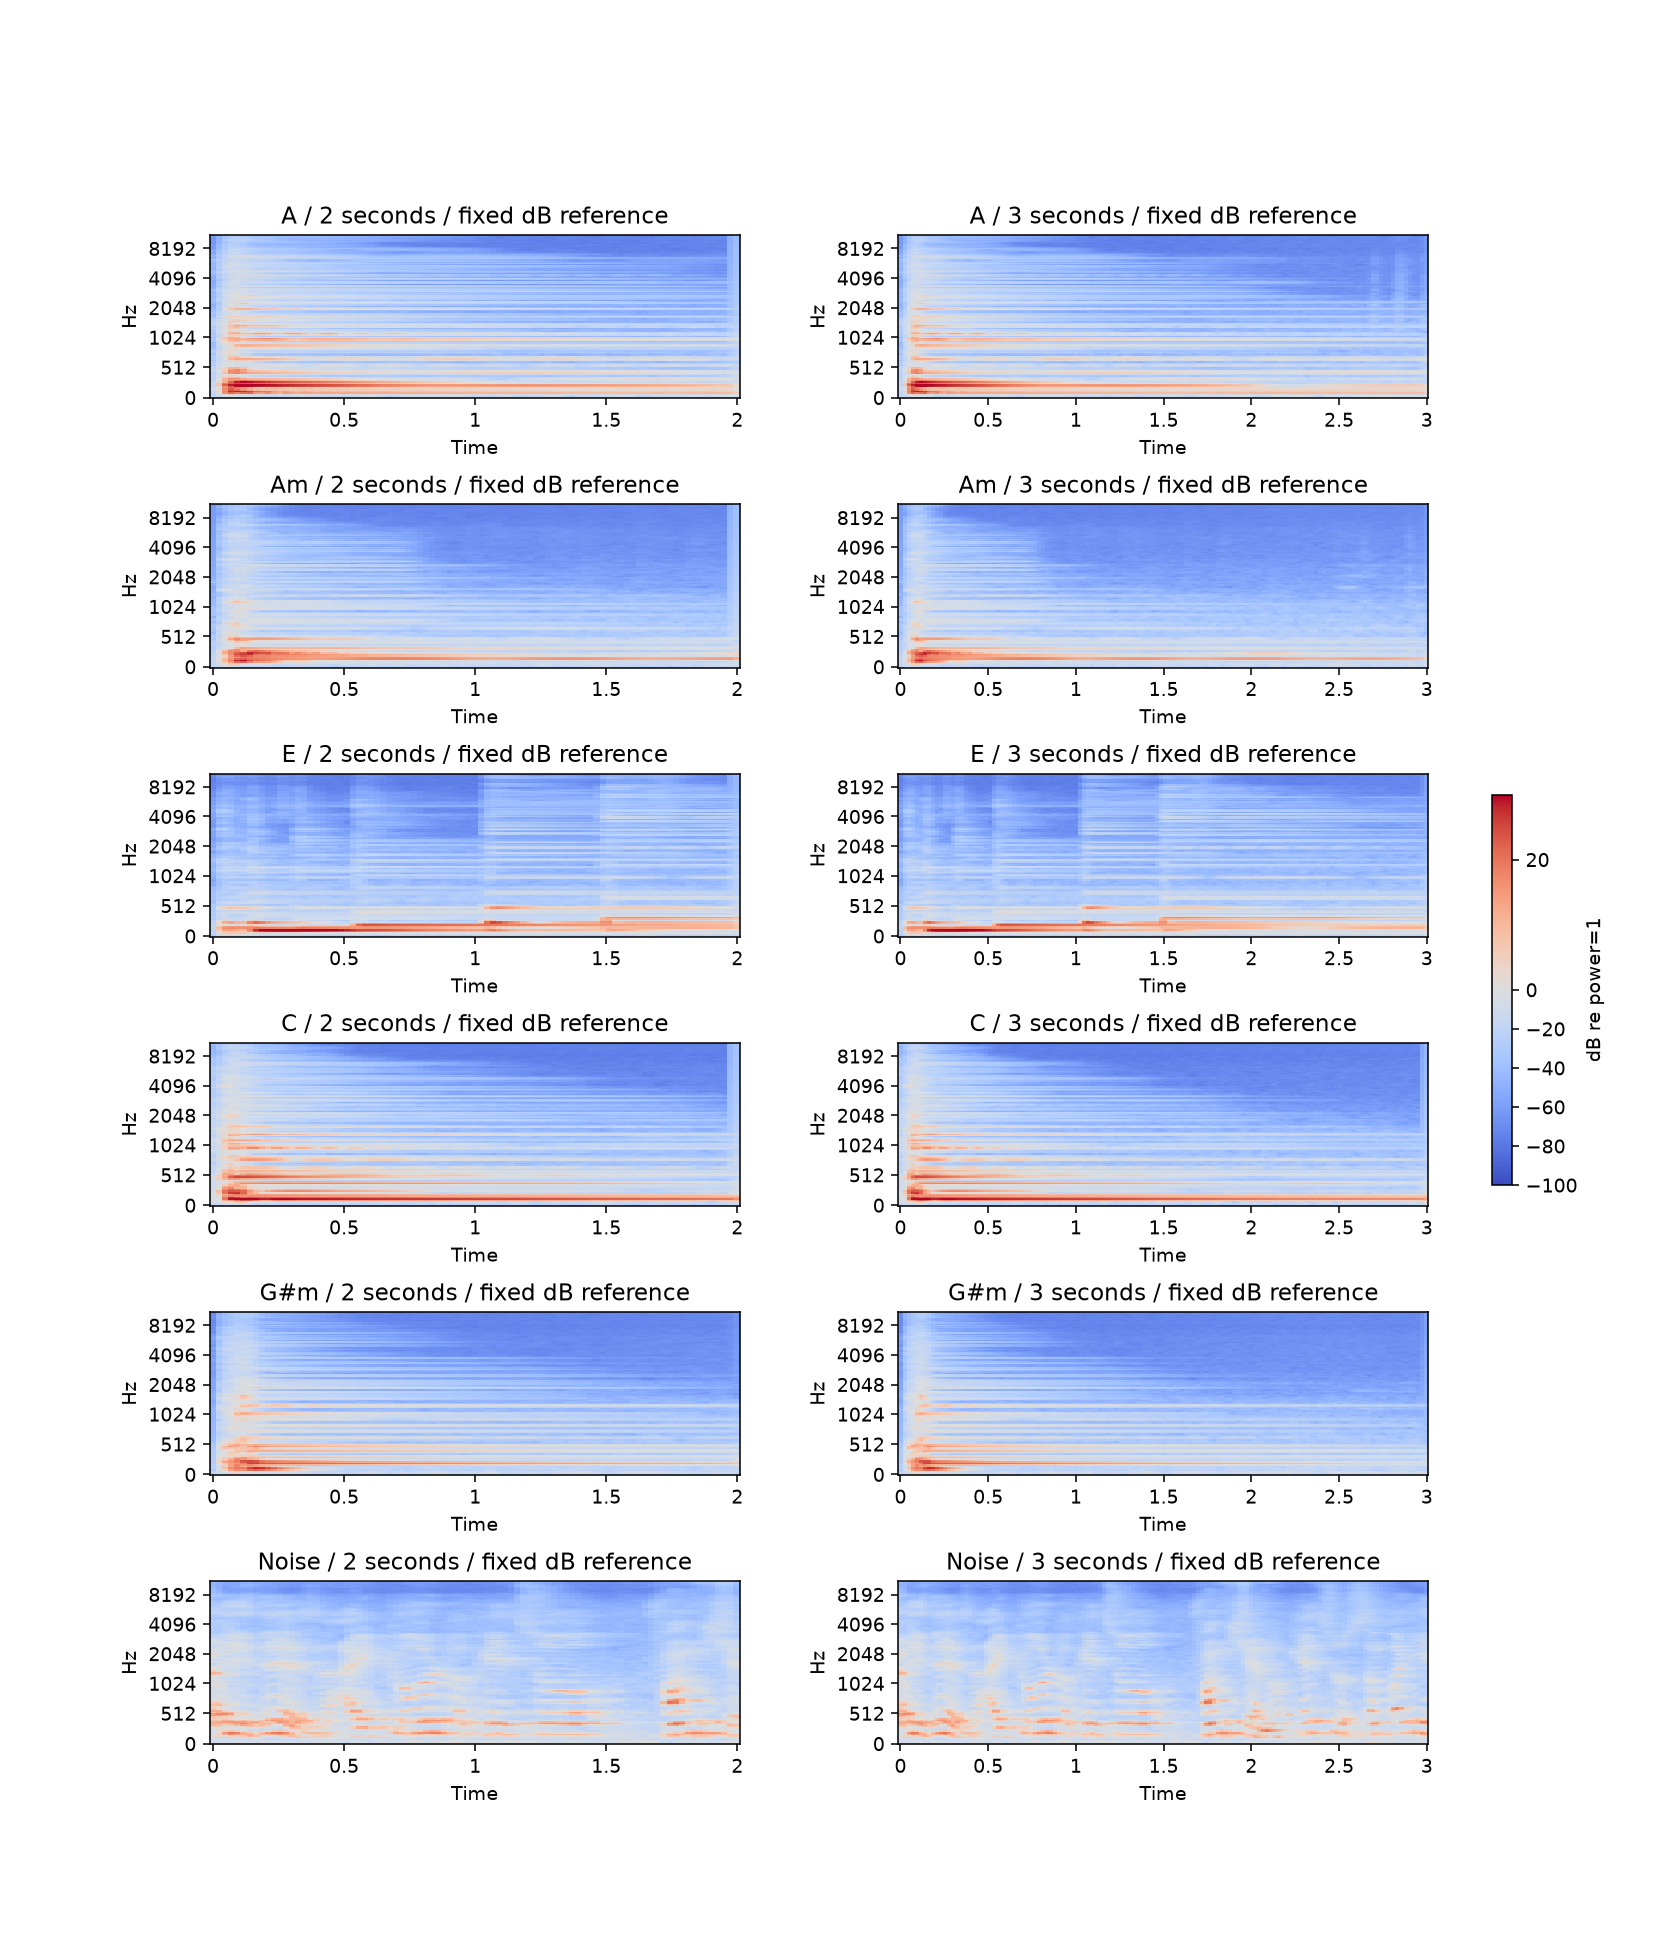

In [3]:
import numpy as np
for duration in [2,3]:
    data=np.load(root/f"data/processed/train_{duration}s.npz")
    print(duration,"seconds",data["mel"].shape,data["baseline"].shape)
display(Image(filename=str(root/"data/eda_output/two_vs_three_seconds.png")))

In [4]:
from src.preprocessing.audio import AudioConfig
from src.features.spectral import MelConfig
print(AudioConfig(duration=3.0))
print(MelConfig())
print("Tests verify inference features match cached training transforms.")

AudioConfig(sample_rate=22050, duration=3.0, activity_threshold=0.003, relative_activity_threshold=0.1, frame_ms=20.0, preroll_ms=40.0, max_input_seconds=90.0)
MelConfig(n_fft=2048, hop_length=512, n_mels=128, floor_db=-100.0, ceiling_db=30.0)
Tests verify inference features match cached training transforms.
